In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import nuels_fun_with_peptides as nfp

protein_map = nfp.read_fasta("../data/sample_proteins.fasta")                   #change here to your own pathway

protein_map

{'P11802': 'MATSRYEPVAEIGVGAYGTVYKARDPHSGHFVALKSVRVPNGGGGGGGLPISTVREVALLRRLEAFEHPNVVRLMDVCATSRTDREIKVTLVFEHVDQDLRTYLDKAPPPGLPAETIKDLMRQFLRGLDFLHANCIVHRDLKPENILVTSGGTVKLADFGLARIYSYQMALTPVVVTLWYRAPEVLLQSTYATPVDMWSVGCIFAEMFRRKPLFCGNSEADQLGKIFDLIGLPPEDDWPRDVSLPRGAFPPRGPRPVQSVVPEMEESGAQLLLEMLTFNPHKRISAFRALQHSYLHKDEGNPE',
 'A0A087WTH1': 'MEDEEKAVEILGNTEAAHPPSPIRCCWLRLRCLAATSIICGCSCLGVMALVFAIKAEERHKAGRSEEAVRWGARARKLILASFAVWLAVLILGPLLLWLLSYAIAQAPEPTIDERE',
 'A0A087WTH5': 'MVIEWERPRMILSNTTAVTPFLTKLWQETVQQGGNMSGLARRSPRSGDGKLEALYVLMVLGFFGFFTLGIMLSYIRSKKLEHSNDPFNVYIESNAWQEKDKAYVQARVLESYRSCYVVENHLAIEQPNTHLPETKPSP'}

In [12]:
from nuels_fun_with_peptides.variables import enzyme_cleavage_patterns
cleavege_pattern = enzyme_cleavage_patterns['LysC']                             #change/edit the library and the enzyme

nfp.digest_protein_sequence(protein_map["P11802"], cleavege_pattern)

['MATSRYEPVAEIGVGAYGTVYK',
 'ARDPHSGHFVALK',
 'VTLVFEHVDQDLRTYLDK',
 'APPPGLPAETIK',
 'DLMRQFLRGLDFLHANCIVHRDLK',
 'PENILVTSGGTVK',
 'PLFCGNSEADQLGK',
 'RISAFRALQHSYLHK',
 'DEGNPE']

In [13]:
digested_peptide_map = nfp.digest_protein_collection(protein_map,
    cleave_pattern=cleavege_pattern,
    min_pep_len=5,
    max_pep_len=30,
)

In [14]:
nfp.compute_sequence_coverage(protein_map["P11802"], digested_peptide_map["P11802"])

45.21452145214522

In [15]:
digested_peptide_list = sum(digested_peptide_map.values(), [])                  #make sure youre input is a list

retention_time_map = nfp.predict_lc_retention_times(digested_peptide_list)

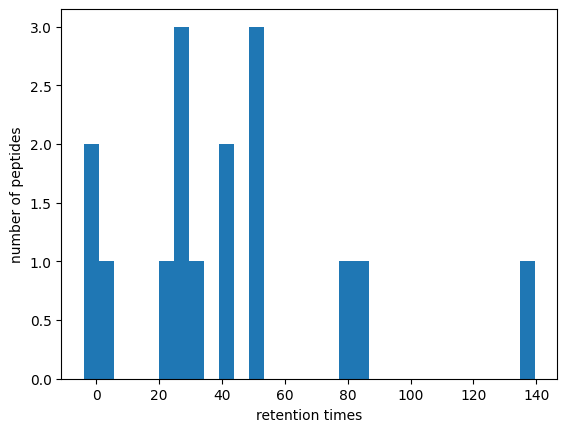

In [16]:
nfp.plot_retention_time(retention_time_map)

In [17]:
select_peps = nfp.select_retention_time_window(
    peptide_rt_map=retention_time_map,
    lower_ret_time=0,
    upper_ret_time=50,
)

In [20]:
nfp.calculate_mol_mass("PEPTIDE", nfp.amino_acid_mass_dalton)[1]

{'PEPTIDE': 781.84}

In [25]:
mol_mass_map = nfp.calculate_mol_mass_collection(select_peps, nfp.amino_acid_mass_dalton)
mol_mass_map

{'ARDPHSGHFVALK': 1416.61,
 'APPPGLPAETIK': 1172.41,
 'PENILVTSGGTVK': 1296.4899999999998,
 'PLFCGNSEADQLGK': 1460.6400000000003,
 'RISAFRALQHSYLHK': 1809.12,
 'AEERHK': 750.8199999999999,
 'AGRSEEAVRWGARARK': 1782.01,
 'LWQETVQQGGNMSGLARRSPRSGDGK': 2798.0900000000006,
 'LEHSNDPFNVYIESNAWQEK': 2402.5699999999997}

In [27]:
mz_collection_map = nfp.calculate_mz_collection(mol_mass_map)
mz_collection_map

{'ARDPHSGHFVALK': 709.3119999999999,
 'APPPGLPAETIK': 587.212,
 'PENILVTSGGTVK': 649.2519999999998,
 'PLFCGNSEADQLGK': 731.3270000000001,
 'RISAFRALQHSYLHK': 905.5669999999999,
 'AEERHK': 376.417,
 'AGRSEEAVRWGARARK': 892.012,
 'LWQETVQQGGNMSGLARRSPRSGDGK': 1400.0520000000004,
 'LEHSNDPFNVYIESNAWQEK': 1202.292}

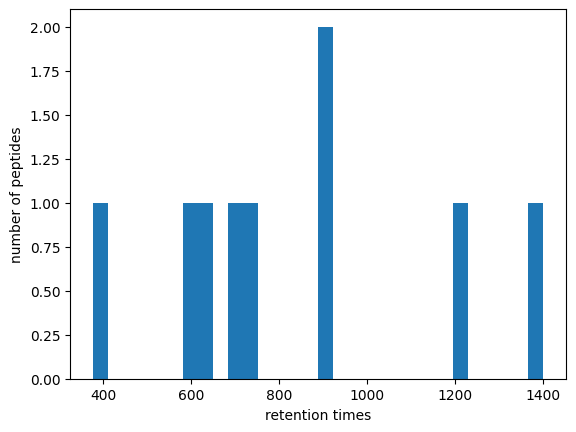

In [28]:
nfp.plot_retention_time(mz_collection_map)

In [29]:
nfp.fragment_peptide('MATSR')

['M', 'MA', 'MAT', 'MATS', 'R', 'RS', 'RST', 'RSTA']

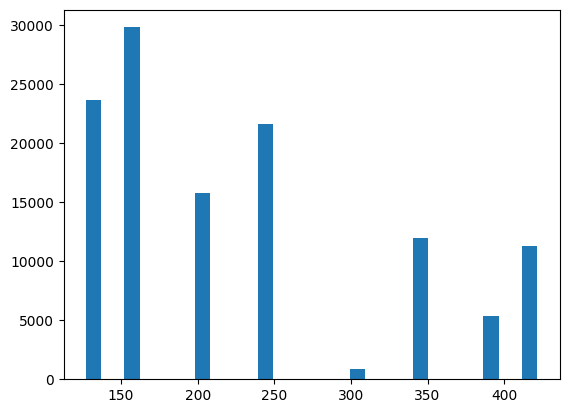

In [30]:
mypep = 'MATSR'
frags = nfp.fragment_peptide(mypep)
mass_map_ms2 = nfp.calculate_mol_mass_collection(frags, nfp.amino_acid_mass_dalton)
mz2_map = nfp.calculate_mz_collection(mass_map_ms2, 1)
nfp.plot_spectrum(mz2_map)